# Previsioni meteo archiviate GFS — Francesco

Consegna BSML: temperatura, umidità relativa e nuvolosità per Milano, Torino, Bologna, Roma, Napoli e Palermo, dal **1 gennaio 2022 al 31 dicembre 2025**, con frequenza oraria UTC.

Questo notebook legge e controlla il dataset finale già raccolto: **35.064 ore × 6 città = 210.384 righe**, con 631.152 valori meteo. Non addestra il modello di domanda elettrica.

La tabella è in formato lungo: `issue_time_utc`, `target_time_utc`, `city` e variabili previste, con metadati temporali aggiuntivi. È il file separato delle previsioni archiviate previsto dalla task. Il precedente `weather_clean.csv` e il precedente `download_weather.py` sono stati indicati dall'autore come superati.

La raccolta da NOAA è opzionale e disattivata: l'esecuzione ordinaria usa soltanto i file già consegnati.

## 1. Ambiente e percorsi

Eseguire dalla copia locale del repository. In Colab, rendere prima disponibili le cartelle del repository oppure impostare la variabile d'ambiente `BSML_REPO_ROOT`. Per rivedere i dati bastano `pandas` e `matplotlib`; `eccodes` serve soltanto alla raccolta opzionale. Le dipendenze sono elencate in `requirements-weather.txt` senza modificare quelle del gruppo.

In [1]:
from pathlib import Path
import os
import sys
import json
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

configured_root = os.environ.get('BSML_REPO_ROOT')
if configured_root:
    REPO_ROOT = Path(configured_root).expanduser().resolve()
else:
    REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                      if (p / 'data/processed/weather_forecast_clean.csv').is_file()), None)
    if REPO_ROOT is None:
        raise FileNotFoundError('Dataset assente: aprire il notebook nella copia del repository o impostare BSML_REPO_ROOT.')

DATA_DIR = REPO_ROOT / 'data/processed'
FIGURE_DIR = REPO_ROOT / 'notebooks/francesco/figures'
CSV_PATH = DATA_DIR / 'weather_forecast_clean.csv'
VARIABLES = ['temp_c', 'humidity_pct', 'cloud_cover_pct']
CITIES = ['milano', 'torino', 'bologna', 'roma', 'napoli', 'palermo']
print('Repository:', REPO_ROOT.name)
print('Dataset:', CSV_PATH.relative_to(REPO_ROOT))
print('pandas:', pd.__version__)

Repository: repository_files
Dataset: data/processed/weather_forecast_clean.csv
pandas: 2.2.3


## 2. Fonte e scelta temporale

- Fonte: [NOAA GFS 0,25° su AWS](https://registry.opendata.aws/noaa-gfs-bdp-pds/).
- Per ogni giorno target si usa il run inizializzato alle **12 UTC del giorno precedente**. Le scadenze sono da 12 a 35 ore: la previsione riguarda il giorno target, non il meteo del giorno prima.
- Cutoff adottato: **00:00 UTC all'inizio del giorno target**.
- `issue_time_utc` e `run_time_utc` identificano l'inizializzazione nominale del run, non l'orario ufficiale di pubblicazione.
- `archive_last_modified_utc` è il massimo Last-Modified S3 dei tre campi usati. È evidenza dell'archivio, non la prima pubblicazione ufficiale.
- Temperatura a 2 m convertita da kelvin a °C; umidità a 2 m e nuvolosità totale in %. Si estrae il punto di griglia più vicino alle coordinate della città, senza interpolazione.
- Nessuna imputazione, nessun riempimento con zero e nessuna sostituzione con ERA5.

**Limite da confermare con il team:** il cutoff scelto deve coincidere con il momento operativo in cui si produce la previsione di domanda e con il protocollo del confronto con Terna. I controlli successivi verificano la regola scelta, non risolvono questa decisione progettuale.

In [2]:
metadata = json.loads((DATA_DIR / 'weather_forecast_metadata.json').read_text())
assert hashlib.sha256(CSV_PATH.read_bytes()).hexdigest() == metadata['csv_sha256']
dataset = pd.read_csv(CSV_PATH)
time_columns = ['issue_time_utc', 'target_time_utc', 'run_time_utc',
                'cutoff_time_utc', 'archive_last_modified_utc']
for column in time_columns:
    dataset[column] = pd.to_datetime(dataset[column], utc=True, errors='raise')
for column in VARIABLES:
    dataset[column] = pd.to_numeric(dataset[column], errors='raise')
display(dataset.head(6))
display(pd.read_csv(DATA_DIR / 'weather_forecast_data_dictionary.csv'))

issue_time_utc,target_time_utc,city,model,run_time_utc,cutoff_time_utc,lead_hours,archive_last_modified_utc,temp_c,humidity_pct,cloud_cover_pct
2021-12-31 12:00:00+00:00,2022-01-01 00:00:00+00:00,bologna,gfs_global_0p25,2021-12-31 12:00:00+00:00,2022-01-01 00:00:00+00:00,12,2021-12-31 15:39:16+00:00,8.650898,86.5,5.0
2021-12-31 12:00:00+00:00,2022-01-01 00:00:00+00:00,milano,gfs_global_0p25,2021-12-31 12:00:00+00:00,2022-01-01 00:00:00+00:00,12,2021-12-31 15:39:16+00:00,7.700898,64.8,1.7
2021-12-31 12:00:00+00:00,2022-01-01 00:00:00+00:00,napoli,gfs_global_0p25,2021-12-31 12:00:00+00:00,2022-01-01 00:00:00+00:00,12,2021-12-31 15:39:16+00:00,15.000898,70.6,0.0
2021-12-31 12:00:00+00:00,2022-01-01 00:00:00+00:00,palermo,gfs_global_0p25,2021-12-31 12:00:00+00:00,2022-01-01 00:00:00+00:00,12,2021-12-31 15:39:16+00:00,9.580898,74.2,5.0
2021-12-31 12:00:00+00:00,2022-01-01 00:00:00+00:00,roma,gfs_global_0p25,2021-12-31 12:00:00+00:00,2022-01-01 00:00:00+00:00,12,2021-12-31 15:39:16+00:00,9.550898,77.3,4.9
2021-12-31 12:00:00+00:00,2022-01-01 00:00:00+00:00,torino,gfs_global_0p25,2021-12-31 12:00:00+00:00,2022-01-01 00:00:00+00:00,12,2021-12-31 15:39:16+00:00,7.530898,71.3,4.9


column,meaning,unit
issue_time_utc,Nominal GFS model-run initialisation; not official publication time,UTC
target_time_utc,Forecast valid time,UTC
city,Requested Italian city,NaN
temp_c,Forecast 2-metre temperature,Celsius
humidity_pct,Forecast 2-metre relative humidity,percent
cloud_cover_pct,Forecast instantaneous total cloud cover,percent
model,GFS global forecast product on the 0.25-degree grid,NaN
run_time_utc,Nominal GFS model-run initialisation,UTC
lead_hours,Hours between model initialisation and forecast valid time,hours
archive_last_modified_utc,"Latest S3 object modification among successfully extracted fields; conservative archive evidence, not first official publication",UTC


## 3. Copertura, duplicati, NaN e valori fuori intervallo

Una riga rappresenta una città a un'ora target. I controlli richiedono tutte le combinazioni delle 35.064 ore UTC con le sei città. Gli intervalli di screening sono −50–60 °C per la temperatura e 0–100% per umidità e nuvolosità. Eventuali valori fuori intervallo vengono segnalati, non corretti automaticamente.

In [3]:
expected_times = pd.date_range('2022-01-01', '2026-01-01', freq='h', inclusive='left', tz='UTC')
expected_keys = pd.MultiIndex.from_product([expected_times, CITIES], names=['target_time_utc', 'city'])
actual_keys = pd.MultiIndex.from_frame(dataset[['target_time_utc', 'city']])
duplicate_rows = int(dataset.duplicated(['target_time_utc', 'city']).sum())
missing_keys = expected_keys.difference(actual_keys)
unexpected_keys = actual_keys.difference(expected_keys)
assert len(dataset) == 210384
assert set(dataset['city']) == set(CITIES)
assert duplicate_rows == 0 and len(missing_keys) == 0 and len(unexpected_keys) == 0

quality_rows = []
for city in CITIES:
    part = dataset.loc[dataset['city'].eq(city)]
    for variable in VARIABLES:
        values = part[variable]
        low, high = (-50, 60) if variable == 'temp_c' else (0, 100)
        quality_rows.append({'city': city, 'variable': variable,
                             'expected_hours': len(expected_times), 'rows': len(part),
                             'missing_values': int(values.isna().sum()),
                             'flagged_values': int((values.notna() & ~values.between(low, high)).sum())})
quality = pd.DataFrame(quality_rows)
display(quality)
missing_count = int(quality['missing_values'].sum())
flagged_count = int(quality['flagged_values'].sum())
assert missing_count == 0 and flagged_count == 0
provided_report = pd.read_csv(DATA_DIR / 'weather_forecast_missing_values_report.csv')
assert len(provided_report) == 18
assert provided_report['expected_hours'].eq(len(expected_times)).all()
assert int(provided_report['missing_count'].sum()) == missing_count
print(f'Copertura completa: {len(expected_times):,} ore, {len(dataset):,} righe, 48 mesi.')
print(f'Duplicati: {duplicate_rows}; combinazioni mancanti: {len(missing_keys)}; NaN: {missing_count}; segnalazioni: {flagged_count}.')

Copertura completa: 35,064 ore, 210,384 righe, 48 mesi.
Duplicati: 0; combinazioni mancanti: 0; NaN: 0; segnalazioni: 0.


city,variable,expected_hours,rows,missing_values,flagged_values
milano,temp_c,35064,35064,0,0
milano,humidity_pct,35064,35064,0,0
milano,cloud_cover_pct,35064,35064,0,0
torino,temp_c,35064,35064,0,0
torino,humidity_pct,35064,35064,0,0
torino,cloud_cover_pct,35064,35064,0,0
bologna,temp_c,35064,35064,0,0
bologna,humidity_pct,35064,35064,0,0
bologna,cloud_cover_pct,35064,35064,0,0
roma,temp_c,35064,35064,0,0


## 4. Verifica della regola temporale e della provenienza

Il manifest compresso contiene una riga per ora e variabile GFS: URL, intervallo di byte, SHA-256 del messaggio originale, SHA-256 dell'indice e Last-Modified. Sono **105.192 messaggi sorgente**, ognuno usato per estrarre tutte e sei le città. I GRIB binari e i registri completi delle estrazioni restano nei backup originali; questo notebook non ne certifica la presenza sul PC.

Nella preparazione della consegna, tutti i 631.152 valori sono stati confrontati con i registri di estrazione. I controlli qui sotto verificano il CSV, il manifest e le relative impronte; non decodificano nuovamente i GRIB.

In [4]:
cutoffs = dataset['target_time_utc'].dt.normalize()
expected_runs = cutoffs - pd.Timedelta(days=1) + pd.Timedelta(hours=12)
expected_leads = (dataset['target_time_utc'] - dataset['run_time_utc']).dt.total_seconds() / 3600
assert dataset['cutoff_time_utc'].eq(cutoffs).all()
assert dataset['run_time_utc'].eq(expected_runs).all()
assert dataset['issue_time_utc'].eq(dataset['run_time_utc']).all()
assert dataset['lead_hours'].eq(expected_leads).all()
assert dataset['lead_hours'].between(12, 35).all()
assert dataset['archive_last_modified_utc'].ge(dataset['run_time_utc']).all()
assert dataset['archive_last_modified_utc'].lt(dataset['cutoff_time_utc']).all()

manifest_path = DATA_DIR / 'weather_forecast_sources.csv.gz'
assert hashlib.sha256(manifest_path.read_bytes()).hexdigest() == metadata['source_manifest_sha256']
manifest = pd.read_csv(manifest_path)
assert len(manifest) == len(expected_times) * len(VARIABLES)
assert not manifest.duplicated(['target_time_utc', 'variable']).any()
assert set(manifest['variable']) == set(VARIABLES)
manifest_times = pd.to_datetime(manifest['target_time_utc'], utc=True)
manifest_runs = pd.to_datetime(manifest['issue_time_utc'], utc=True)
manifest_cutoffs = pd.to_datetime(manifest['cutoff_time_utc'], utc=True)
manifest_modified = pd.to_datetime(manifest['archive_last_modified_utc'], utc=True)
manifest_keys = pd.MultiIndex.from_arrays([manifest_times, manifest['variable']])
expected_source_keys = pd.MultiIndex.from_product([expected_times, VARIABLES])
assert len(expected_source_keys.difference(manifest_keys)) == 0
assert manifest_modified.ge(manifest_runs).all() and manifest_modified.lt(manifest_cutoffs).all()
assert manifest['sha256'].str.fullmatch('[0-9a-f]{64}').all()
assert manifest['index_sha256'].str.fullmatch('[0-9a-f]{64}').all()
print(f'Manifest verificato: {len(manifest):,} messaggi sorgente.')
print('Tutti i metadati di archivio precedono il cutoff adottato.')
print('Conferma del cutoff operativo con il team: ancora da documentare.')

Manifest verificato: 105,192 messaggi sorgente.
Tutti i metadati di archivio precedono il cutoff adottato.
Conferma del cutoff operativo con il team: ancora da documentare.


## 5. Grafici delle temperature previste

Le medie giornaliere e mensili sono calcolate sulle temperature previste per le ore target. Sono grafici descrittivi del dataset GFS, non misure dell'errore di previsione rispetto a osservazioni.

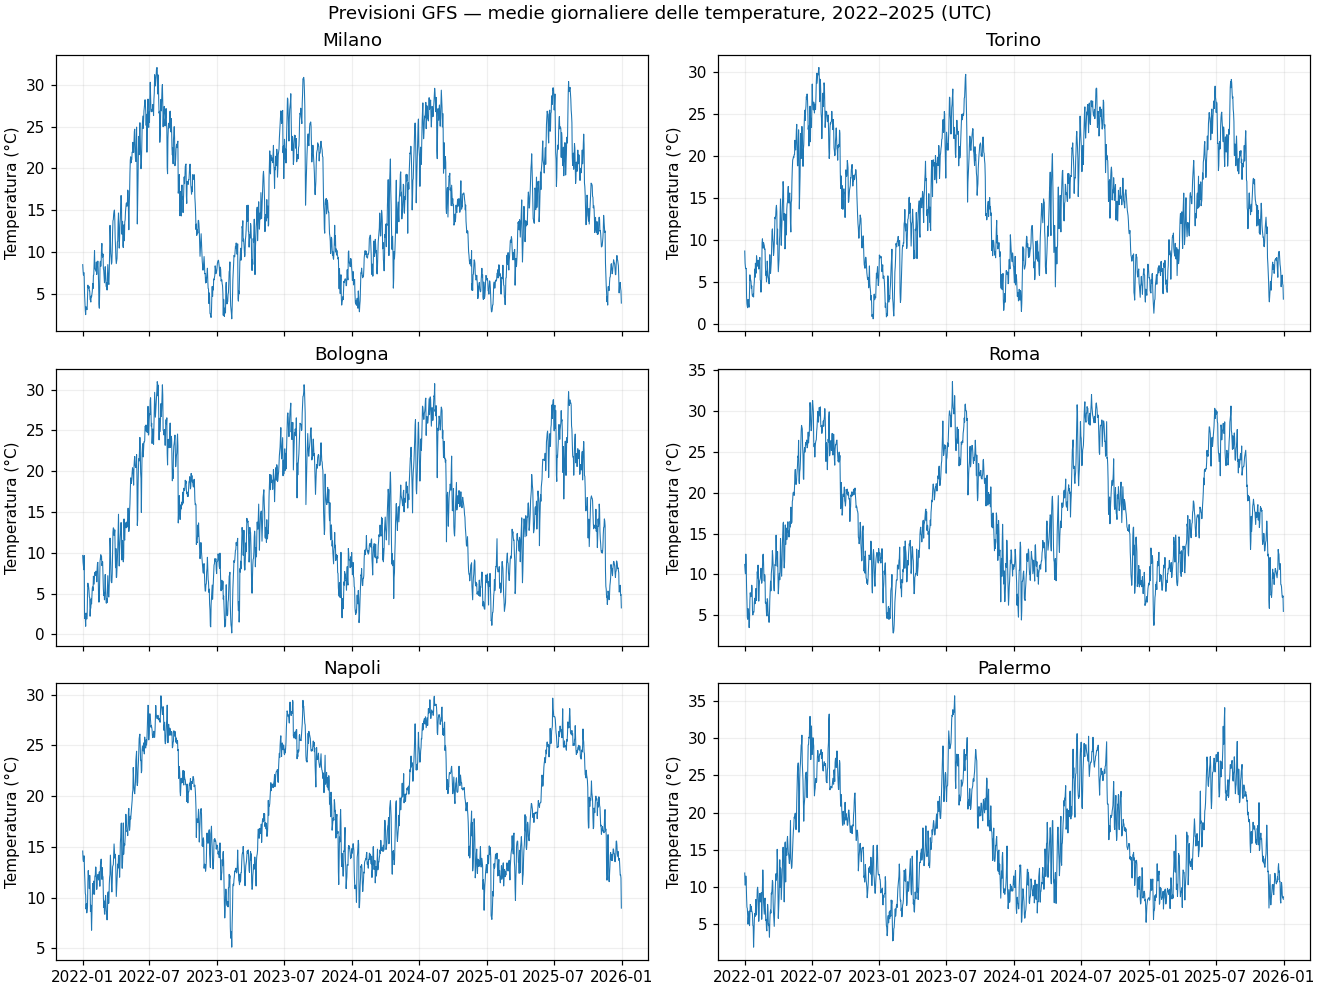

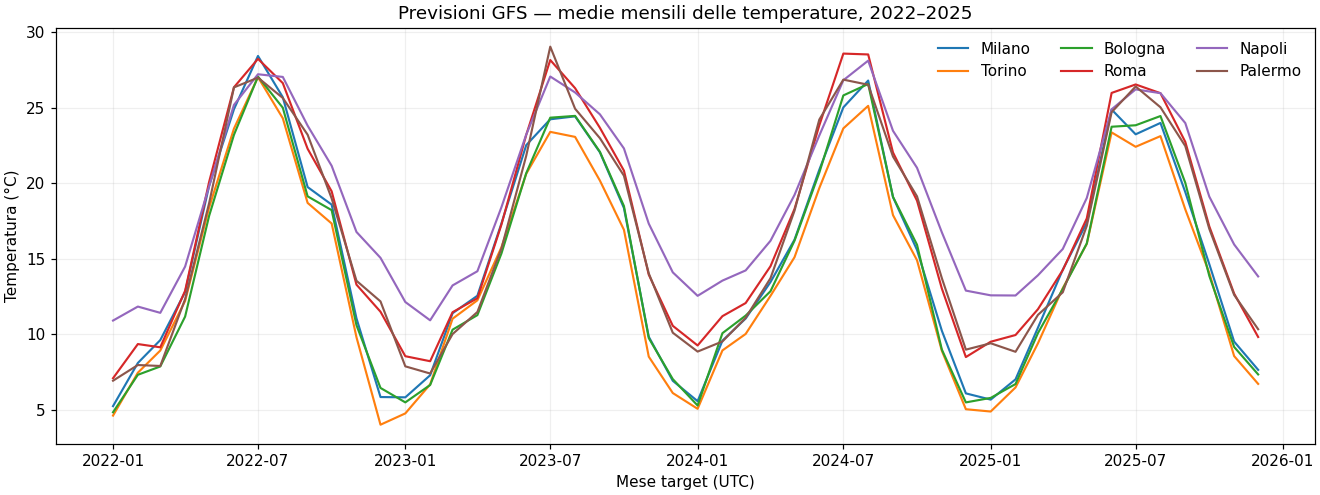

In [5]:
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
wide = dataset.pivot(index='target_time_utc', columns='city', values='temp_c').sort_index()
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True, layout='constrained')
for ax, city in zip(axes.flat, CITIES):
    daily = wide[city].resample('D').mean()
    ax.plot(daily.index, daily, linewidth=0.7)
    ax.set(title=city.capitalize(), ylabel='Temperatura (°C)')
    ax.grid(alpha=0.2)
fig.suptitle('Previsioni GFS — medie giornaliere delle temperature, 2022–2025 (UTC)')
fig.savefig(FIGURE_DIR / 'weather_forecast_temperature_daily.png', dpi=130)
display(fig)
plt.close(fig)

fig, ax = plt.subplots(figsize=(12, 4.5), layout='constrained')
monthly = wide.resample('MS').mean()
for city in CITIES:
    ax.plot(monthly.index, monthly[city], label=city.capitalize(), linewidth=1.4)
ax.set(xlabel='Mese target (UTC)', ylabel='Temperatura (°C)',
       title='Previsioni GFS — medie mensili delle temperature, 2022–2025')
ax.grid(alpha=0.2)
ax.legend(ncol=3, frameon=False)
fig.savefig(FIGURE_DIR / 'weather_forecast_temperature_monthly.png', dpi=130)
display(fig)
plt.close(fig)

## 6. Raccolta riproducibile, opzionale

Il nuovo `download_weather.py` contiene le funzioni del notebook originale, con percorsi configurabili e senza caricamenti interattivi da Colab. La regola temporale, la selezione dei campi e il metodo di estrazione sono mantenuti.

La lettura del dataset finale non richiede questa sezione. Per raccogliere dati da zero, installare `requirements-weather.txt`, scegliere una cartella persistente con spazio adeguato e abilitare esplicitamente `RUN_COLLECTION`. Ogni esecuzione elabora un solo mese e conserva i checkpoint. I messaggi GRIB2 originali sono scaricati senza modificarne i byte tramite richieste HTTP Range; non si scaricano tutti i campi dei file globali.

Una raccolta non prova che tutti i backup siano conservati: la loro inventariazione va eseguita separatamente. Il notebook non avvia trasferimenti dal browser e non scarica automaticamente decine di GB.

In [6]:
RUN_COLLECTION = False
RAW_ROOT = None  # Esempio: Path('/percorso/persistente/weather_gfs_dataset')

if RUN_COLLECTION:
    if RAW_ROOT is None:
        raise ValueError('Impostare RAW_ROOT su una cartella persistente prima di raccogliere dati.')
    if str(REPO_ROOT) not in sys.path:
        sys.path.insert(0, str(REPO_ROOT))
    from download_weather import collect_batch
    collected, completed_months, full_period_checked = collect_batch(
        Path(RAW_ROOT), '2022-01-01', '2025-12-31',
        months_per_run=1, retry_month=None, workers=4
    )
    print('Mesi elaborati:', len(completed_months), 'Righe:', len(collected))
else:
    print('Raccolta disattivata: nessuna richiesta di rete eseguita.')

Raccolta disattivata: nessuna richiesta di rete eseguita.


## 7. Integrazione nel progetto

- File delle previsioni: `data/processed/weather_forecast_clean.csv`.
- La chiave per il join con domanda e calendario è `target_time_utc`; prima del join occorre trasformare le sei città in colonne, ad esempio `temp_milano_c`, mantenendo separati i metadati del run.
- Il file di meteo storico/ricostruito, se mantenuto, deve restare separato e documentato. Non usare il vecchio `weather_clean.csv` indicato dall'autore come sbagliato senza verificarlo.
- I riferimenti al vecchio `weather_clean.csv` nei notebook di merge vanno aggiornati dal team secondo il formato concordato. Questo notebook non modifica gli altri file del progetto.
- Non sostituire valori mancanti con osservazioni, zero o interpolazione. Il dataset consegnato non contiene NaN meteo.
- I checkpoint ZIP servono al recupero delle sessioni, non sono i file finali da usare nell'analisi.

Fonti metodologiche: [NOAA GFS](https://registry.opendata.aws/noaa-gfs-bdp-pds/), [ecCodes](https://sites.ecmwf.int/docs/eccodes/), [S3 Last-Modified](https://docs.aws.amazon.com/AmazonS3/latest/API/API_HeadObject.html).